# Histogram filter

Assume we have a robot that can be in one of five blocks. With no other info we calculate the probability of the robot being in each such and plot a histogram of the probabilities:

In [1]:
from math import *
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal

<BarContainer object of 5 artists>

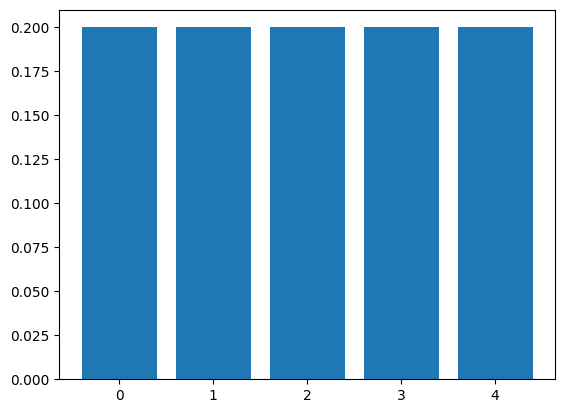

In [2]:
# Start with a uniform belief distribution over all five possible robot locations.
# Why uniform: before any sensing has taken place, there is no information that
# makes one block more likely than any other. Assigning equal probability to every
# block is the only unbiased starting assumption — the "uninformative prior" in
# Bayesian terms. A wrong confident prior would bias the filter; starting maximally
# uncertain lets measurements correct it quickly and without prejudice.
# Why the values must sum to 1: p represents a probability distribution over "which
# block the robot occupies". Since the robot is in exactly one block at any moment,
# the total probability across all blocks must equal 1 — a hard constraint for any
# valid probability distribution. Here 1/5 × 5 = 1 satisfies that constraint.
no_of_blocks = 5
prb = 1/5

p = [prb, prb, prb, prb, prb]

plt.bar(range(no_of_blocks), p)

Now we say that each block is either red or green and that our robot can sense that colour. We multiply all the correct sensings with 0.6 and the incorrect with 0.2. These values are arbitrary and just represent that the robot has a higher probability to be at a red block if that is what is measured.

In the following we define the world and make a function that calculates the new probabilities by using the measurement. We then try it out with a measurement of 'red'.

Notice that we divide each probability with the sum of all probabilities in order to get something that adds up to one.

[0.11111111 0.33333333 0.33333333 0.11111111 0.11111111]


<BarContainer object of 5 artists>

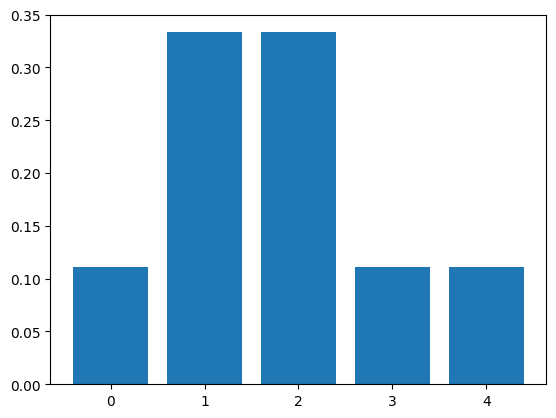

In [3]:
# Implement the measurement update step — revise the belief after the robot's
# colour sensor reports the colour of its current block.
# Why multiply by pHit for matching cells and pMiss for mismatching ones: this
# is Bayes' rule applied cell by cell. A cell whose colour matches the measurement
# ('red') is consistent with what the sensor reported, so its probability gets
# scaled up by pHit=0.6; a cell whose colour contradicts the measurement gets
# scaled down by pMiss=0.2. The ratio pHit/pMiss encodes sensor reliability —
# a perfect sensor would use 1 and 0; a completely random one would use equal
# values (no information gained).
# Why divide by sum(q) at the end: after multiplying each entry independently,
# the values no longer sum to 1 and are no longer a valid probability distribution.
# Dividing every entry by the total sum re-normalises the distribution back to 1.
# This normalisation step is mandatory in every Bayesian measurement update.
no_of_blocks = 5
prb = 1/5
p = [prb, prb, prb, prb, prb]

world = ['green', 'red', 'red', 'green', 'green']
z = 'red' # Measurement
pHit = 0.6
pMiss = 0.2

def sense(p,z):
    q = []
    for i in range(len(world)):
        hit = (z == world[i]) # True if measurement matches this part of the world, false if not.
        q.append(p[i]*(hit * pHit + (1- hit) * pMiss))
        
    q = np.array(q)/sum(q) # Divide the probability with the sum of all probabilities, to make it add up to 1.
    return q


q = sense(p,z)
print(q)

plt.bar(range(no_of_blocks), q)

Next we make a function that moves the robot. This is easily done using the numpy roll method:

<BarContainer object of 5 artists>

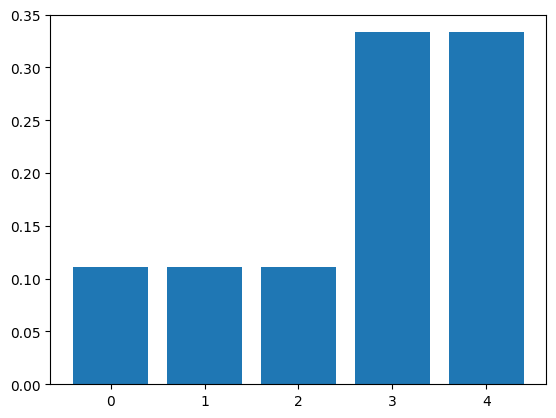

In [4]:
# Implement the motion update step — shift the belief distribution after the
# robot executes a move. This version assumes perfectly accurate movement.
# Why np.roll: if the robot moves U blocks with no error, the probability mass
# that was at position i before the move should now be at position (i+U). np.roll
# performs this shift in one call, including wrap-around at the array boundaries,
# which models a circular world where moving off one end brings you back to the
# other. No probability mass is created or destroyed — it only relocates.
def move(p, U):
    q=np.roll(p,U)
    return q

q = move(q, 2)
plt.bar(range(no_of_blocks), q)

Every time we move there is some uncertainty to the movement, due to measurement uncertainties, etc. We therefore add some uncertainty to the movement. We do this by convolving the uncertainty with the probabilites. We use a scipy filter to do this:

/var/folders/ss/l8vb40xn1b1573h2wlp56d580000gn/T/ipykernel_20847/2292555457.py:18: DeprecationWarning: Please import `convolve1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  q=ndimage.filters.convolve1d(q,move_uncertainty,mode='wrap')


<BarContainer object of 5 artists>

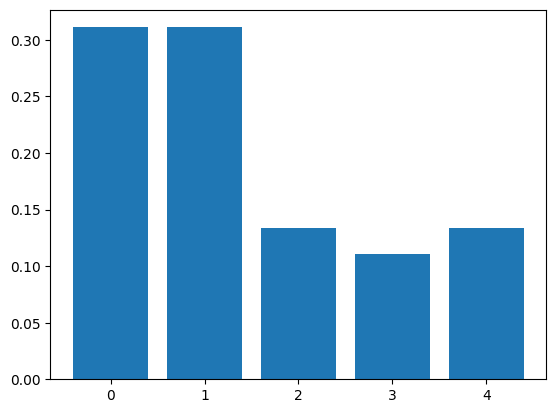

In [5]:
# Refine the motion update to account for real-world movement uncertainty.
# Why convolve with move_uncertainty=[0.1, 0.8, 0.1]: a real robot commanded to
# move U blocks usually lands on the exact target (80% of the time here), but might
# undershoot or overshoot by one block (10% each). Convolution captures this by
# "spreading" each probability mass value to its neighbours according to the kernel
# weights — the resulting distribution reflects all the ways the true landing
# position can deviate from the intended one.
# Why mode='wrap': the circular-world assumption used in np.roll must also apply
# to the convolution — probability near the edge of the array should wrap around
# to the other side rather than vanishing off the boundary.
# Key insight: every move step widens the distribution (increases uncertainty).
# Only the sense step can narrow it back. This asymmetry between motion and
# sensing is fundamental to all Bayesian localisation filters.
move_uncertainty=[0.1 , 0.8, 0.1]

def move(p, U, move_uncertainty):
    q=np.roll(p,U)
    q=ndimage.filters.convolve1d(q,move_uncertainty,mode='wrap')
    return q

q = move(q, 2, move_uncertainty)
plt.bar(range(no_of_blocks), q)

Now let's see what happens if we move the robot a thousand times without sensing anything:

/var/folders/ss/l8vb40xn1b1573h2wlp56d580000gn/T/ipykernel_20847/2292555457.py:18: DeprecationWarning: Please import `convolve1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  q=ndimage.filters.convolve1d(q,move_uncertainty,mode='wrap')


<BarContainer object of 5 artists>

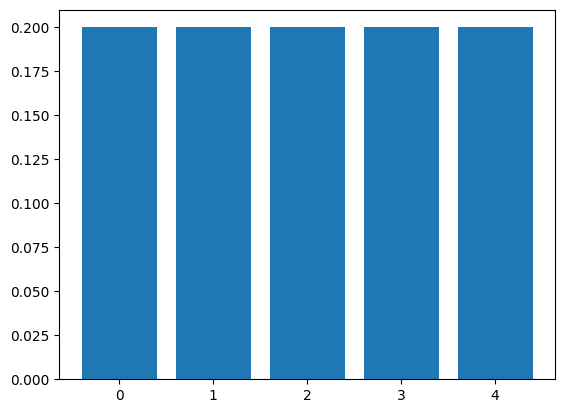

In [6]:
# Stress-test the motion update by moving 1000 times with no sensing whatsoever.
# Why 1000 steps without measurements: each move both shifts the distribution and
# blurs it slightly via convolution. With no sensing to sharpen the belief back,
# uncertainty compounds with every step. After 1000 moves the distribution is
# nearly flat — equivalent to the uninformative starting prior.
# This demonstrates the core limitation of pure dead reckoning: without sensor
# updates, a robot quickly "forgets" its location entirely no matter how carefully
# it tracks its commanded movements. The sense step is what keeps the filter useful.
for i in range(1000):
    q = move(q, 2, move_uncertainty)
    
plt.bar(range(no_of_blocks), q)

Let's try both sensing and moving. We write the full code:

/var/folders/ss/l8vb40xn1b1573h2wlp56d580000gn/T/ipykernel_20847/1541672919.py:32: DeprecationWarning: Please import `convolve1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  q=ndimage.filters.convolve1d(q,move_uncertainty,mode='wrap')


<BarContainer object of 5 artists>

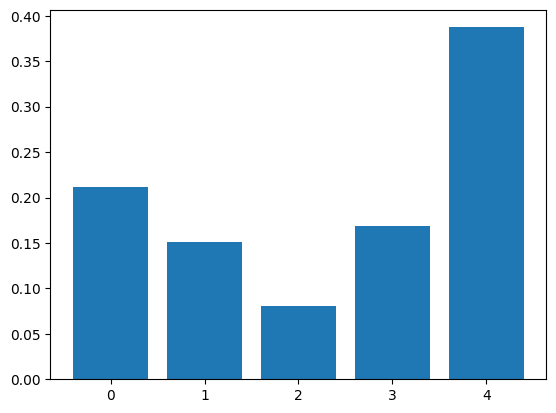

In [7]:
# Full histogram filter: combine the sense and move steps in a loop over time.
# Why sense first and then move each iteration: we measure the robot's current
# environment before commanding it to move, so sensing comes first; the move step
# then shifts the updated (sharpened) belief to anticipate the position after motion.
# The recursive structure — where the output distribution of one cycle becomes the
# prior input of the next — is the defining characteristic of recursive Bayesian
# filters. Sensing concentrates probability mass around plausible locations while
# moving shifts and slightly spreads it. Alternating the two keeps the robot's
# location estimate continuously meaningful despite noisy sensors and imperfect motion.
# We define the world, uncertainties, etc. as before.
no_of_blocks = 5
prb = 1/5
p = [prb, prb, prb, prb, prb]
world = ['green', 'red', 'red', 'green', 'green']
measurements=['red','green']
phit=0.6
pmiss=0.2
movements =[1, 1]
move_uncertainty=[0.1 , 0.8, 0.1]

def sense(p, Z):
    q=[]
    for i in range(len(p)):
        hit = (Z == world[i])
        q.append(p[i]*(hit * phit + (1- hit) * pmiss))

    q = np.array(q)/sum(q)
    return q

def move(p, U, move_uncertainty):
    q=np.roll(p,U)
    q=ndimage.filters.convolve1d(q,move_uncertainty,mode='wrap')
    return q

# We make a loop where we measure and move
for i in range(len(movements)):
    p=sense(p,measurements[i])
    p = move(p, movements[i], move_uncertainty)
    
plt.bar(range(no_of_blocks),p)

# Exercise 1 - Solution
We will now extent the histogram plot to work in 2D. You are given the world map and the move function below. We can now move up, down, left and right in the world. We can plot the map with the probabilities by using plt.imshow.
Insert a sense function that will work in 2D, and loop through the measurements and movements, while showing the probabilities using plt.imshow. You will also need to insert a 2D version of the move_uncertainty.

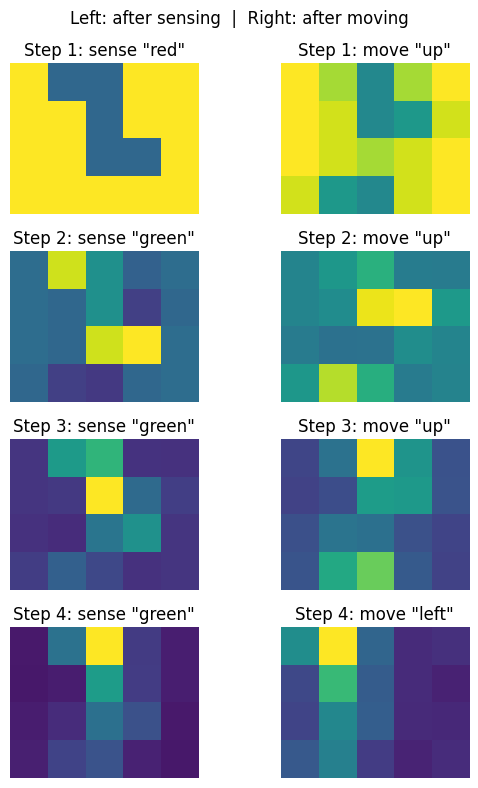

In [8]:
# Extend the histogram filter from 1D (5 blocks) to a 2D grid (4×5 cells).
# The sense step generalises directly: instead of iterating over a 1D list,
# we now iterate over every (row, column) pair in the grid and apply the same
# pHit/pMiss Bayes update per cell. Normalisation is unchanged — divide by the
# grid-wide sum so all values together still add to 1.
# The move step generalises by rolling along the correct numpy axis: axis=0
# (rows) handles up/down motion; axis=1 (columns) handles left/right. The sign
# of the shift matches the direction: moving 'up' decreases row index (shift=-1),
# moving 'down' increases it (shift=+1), and similarly for left/right.
# The 1D uncertainty kernel [0.1, 0.8, 0.1] becomes a 2D 3×3 kernel whose
# nonzero entries are only in the cardinal directions (not the corners), modelling
# slippage strictly along the axis of intended motion. signal.convolve2d with
# boundary='wrap' applies this across the full 2D grid with the same circular
# boundary behaviour as convolve1d used in 1D.
# Displaying both the post-sense and post-move grids at every step (via imshow)
# gives a visual trace of the belief evolving: sensing brightens cells where the
# sensed colour matches the world map; moving then shifts and slightly blurs those
# bright regions to track the robot's new anticipated position.
no_of_blocks = 20
prb = 1/20  # Uniform prior: robot equally likely to be in any of the 20 cells

# The initial belief — a flat 4×5 probability grid (maximum uncertainty)
p = [[prb, prb, prb, prb, prb],
     [prb, prb, prb, prb, prb],
     [prb, prb, prb, prb, prb],
     [prb, prb, prb, prb, prb]]

# The true colour of each cell in the world (unknown to the robot)
world = [['red', 'green', 'green', 'red', 'red'],
         ['red', 'red',   'green', 'red', 'red'],
         ['red', 'red',   'green', 'green', 'red'],
         ['red', 'red',   'red',   'red', 'red']]

measurements = ['red', 'green', 'green', 'green']
phit  = 0.6   # Probability of a correct sensor reading
pmiss = 0.2   # Probability of an incorrect sensor reading
movements = ['up', 'up', 'up', 'left']

# 2D motion uncertainty kernel — models the chance of landing in a neighbouring
# cell instead of the intended one. Must sum to 1.
#   Centre (0.6): robot landed exactly where commanded
#   Cardinal neighbours (0.1 each): slipped one step in that direction
move_uncertainty = [[0,   0.1, 0  ],
                    [0.1, 0.6, 0.1],
                    [0,   0.1, 0  ]]


def sense(p, Z):
    """
    Measurement update (Bayes update) for a 2D grid.

    For each cell, multiply the current probability by phit if the cell colour
    matches the measurement Z, or by pmiss if it doesn't. Then normalise so
    that all probabilities still sum to 1.
    """
    q = [[0 for _ in range(len(p[0]))] for _ in range(len(p))]
    for i in range(len(p)):
        for j in range(len(p[0])):
            hit = (Z == world[i][j])  # True if measurement matches cell colour
            q[i][j] = p[i][j] * (hit * phit + (1 - hit) * pmiss)
    # Normalise: divide every cell by the total so probabilities sum to 1
    total = sum(sum(row) for row in q)
    q = np.array(q) / total
    return q


def move(p, u, move_uncertainty):
    """
    Motion update (prediction step) for a 2D grid.

    np.roll shifts the entire probability grid one step in the commanded
    direction (with wrap-around). The 2D convolution then spreads probability
    mass to neighbouring cells according to move_uncertainty, modelling the
    chance of the robot not landing exactly where intended.
    """
    if u == 'up':
        q = np.roll(p, -1, axis=0)   # Shift rows upward
    elif u == 'down':
        q = np.roll(p,  1, axis=0)   # Shift rows downward
    elif u == 'right':
        q = np.roll(p,  1, axis=1)   # Shift columns right
    elif u == 'left':
        q = np.roll(p, -1, axis=1)   # Shift columns left
    # Convolve with the uncertainty kernel; 'wrap' keeps probability on the grid
    q = signal.convolve2d(q, move_uncertainty, boundary='wrap', mode='same')
    return q


# Alternate sense → move for each step and display both intermediate grids
fig, axes = plt.subplots(len(measurements), 2, figsize=(6, len(measurements) * 2))
fig.suptitle('Left: after sensing  |  Right: after moving')

for i in range(len(measurements)):
    # --- Sense step: sharpen the belief using the colour measurement ---
    p = sense(p, measurements[i])
    axes[i, 0].imshow(p, vmin=0)
    axes[i, 0].set_title(f'Step {i+1}: sense "{measurements[i]}"')
    axes[i, 0].axis('off')

    # --- Move step: shift and spread the belief according to the motion ---
    p = move(p, movements[i], move_uncertainty)
    axes[i, 1].imshow(p, vmin=0)
    axes[i, 1].set_title(f'Step {i+1}: move "{movements[i]}"')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()